# Bike Sharing Demand Analysis and Forecasting

## 1. Introduction
Bike-sharing services support short-distance travel, but fluctuations in daily rental demand can make bicycle availability, staffing and maintenance difficult to plan. Understanding demand patterns and forecasting future rental volumes can provide useful evidence for these operational decisions.
This project analyses the UCI Bike Sharing dataset, which contains daily Capital Bikeshare rental counts alongside weather and calendar information for 2011–2012 (Fanaee-T, 2013). It compares K-means and Ward hierarchical clustering to identify groups of days with similar conditions and examines rental demand across these groups. It also evaluates ARIMA and SARIMA forecasts against a weekly seasonal-naive baseline. The findings are assessed for their usefulness and limitations in supporting system-wide demand planning.

### 1.1 Motivation
Daily fluctuations in bike-sharing demand create challenges for
planning bicycle availability, staffing and maintenance. Understanding
weather and calendar day profiles may help operators anticipate
different demand conditions, while forecasting can support planning
for future rental volumes.

This project investigates whether clustering and time-series models
provide useful evidence for these decisions. As the dataset contains
system-wide daily totals, the findings support broad demand planning
rather than specific station-level redistribution decisions.

### 1.2 Problem Domain
This project focuses on the Transport domain, specifically daily
demand for Capital Bikeshare rentals. The dataset records rental
counts alongside weather and calendar information for 2011–2012.

The problem is to identify meaningful groups of days with similar
conditions and assess how accurately future daily rental totals
can be forecast. Clustering describes day profiles, while ARIMA
and SARIMA model demand over time.

The analysis concerns system-wide daily demand, rather than
individual customer behaviour or station-level bicycle availability.

### 1.3 Assessment Objectives
1. Explore daily bike-sharing demand to identify trends, seasonal
   patterns and unusual observations.
2. Compare K-means and Ward hierarchical clustering using silhouette
   scores, Davies–Bouldin indices and cluster interpretation.
3. Examine how rental demand differs between weather and calendar
   day profiles.
4. Select and evaluate ARIMA/SARIMA forecasts against a weekly
   seasonal-naive baseline using chronological validation and testing.
5. Assess the findings’ usefulness and limitations for planning
   bike availability.

### 1.4 Dataset Rationale
The UCI Bike Sharing dataset was selected because bike sharing belongs
to the Transport domain permitted by the assignment. The daily file
contains 731 observations and 16 columns, covering 1 January 2011 to
31 December 2012. Checks found no missing values, duplicate rows or
missing dates.

Seven weather and calendar features were selected for clustering:
temperature, humidity, wind speed, season, weather category,
working-day status and holiday status. These features allow days
with similar conditions to be grouped. Total daily rentals (`cnt`)
were excluded from the clustering features and used afterwards
to compare demand between groups.

The dated daily rental counts also support time-series exploration
and ARIMA/SARIMA forecasting. Therefore, one dataset supports both
assessment tasks. However, having only two years of historical data
limits the assessment of annual seasonality and the relevance of
the findings to current operations (Fanaee-T, 2013).

Dataset source: https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset

## 2. Data Loading and Quality Checks

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "3"
import pandas as pd

In [2]:
df = pd.read_csv ("day.csv")

### 2.1 Loading and Previewing the Dataset
Load and preview the dataset.

In [3]:
df.head()

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


### 2.2 Dataset Dimensions
Show the number of rows and columns

In [4]:
df.shape

(731, 16)

### 2.3 Data Types and Initial Summary
Check column names, data types, and non-null values

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    str    
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), str(1)
memory usage: 91.5 KB


In [6]:
df.describe()

,instant,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000,731.000000
mean,366.000000,2.496580,0.500684,6.519836,0.028728,2.997264,0.683995,1.395349,0.495385,0.474354,0.627894,0.190486,848.176471,3656.172367,4504.348837
std,211.165812,1.110807,0.500342,3.451913,0.167155,2.004787,0.465233,0.544894,0.183051,0.162961,0.142429,0.077498,686.622488,1560.256377,1937.211452
min,1.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,0.059130,0.079070,0.000000,0.022392,2.000000,20.000000,22.000000
25%,183.500000,2.000000,0.000000,4.000000,0.000000,1.000000,0.000000,1.000000,0.337083,0.337842,0.520000,0.134950,315.500000,2497.000000,3152.000000
50%,366.000000,3.000000,1.000000,7.000000,0.000000,3.000000,1.000000,1.000000,0.498333,0.486733,0.626667,0.180975,713.000000,3662.000000,4548.000000
75%,548.500000,3.000000,1.000000,10.000000,0.000000,5.000000,1.000000,2.000000,0.655417,0.608602,0.730209,0.233214,1096.000000,4776.500000,5956.000000
max,731.000000,4.000000,1.000000,12.000000,1.000000,6.000000,1.000000,3.000000,0.861667,0.840896,0.972500,0.507463,3410.000000,6946.000000,8714.000000


### 2.4 Missing Values and Duplicate Rows
Check for missing values and duplicate rows.

In [7]:
df.isnull().sum()

instant       0
dteday        0
season        0
yr            0
mnth          0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

### 2.5 Date Continuity and Duplicate Dates
Convert the date column and arrange records chronologically/
Check for repeated dates/
Check whether any days are missing

In [9]:
df["dteday"] = pd.to_datetime(df["dteday"])
df = df.sort_values("dteday").reset_index(drop=True)
 
print("Duplicate dates:", df["dteday"].duplicated().sum())

expected_dates = pd.date_range(
    df["dteday"].min(), df["dteday"].max(), freq="D"
)
missing_dates = expected_dates.difference(df["dteday"])

print("Missing days:", len(missing_dates))
print("Start date:", df["dteday"].min().date())
print("End date:", df["dteday"].max().date())

Duplicate dates: 0
Missing days: 0
Start date: 2011-01-01
End date: 2012-12-31


## 3. Exploratory Data Analysis

### 3.1 Summary Statistics

In [10]:
df.describe().round(2)

,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,731.00,731,731.00,731.0,731.00,731.00,731.0,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00,731.00
mean,366.00,2012-01-01 00:00:00,2.50,0.5,6.52,0.03,3.0,0.68,1.40,0.50,0.47,0.63,0.19,848.18,3656.17,4504.35
min,1.00,2011-01-01 00:00:00,1.00,0.0,1.00,0.00,0.0,0.00,1.00,0.06,0.08,0.00,0.02,2.00,20.00,22.00
25%,183.50,2011-07-02 12:00:00,2.00,0.0,4.00,0.00,1.0,0.00,1.00,0.34,0.34,0.52,0.13,315.50,2497.00,3152.00
50%,366.00,2012-01-01 00:00:00,3.00,1.0,7.00,0.00,3.0,1.00,1.00,0.50,0.49,0.63,0.18,713.00,3662.00,4548.00
75%,548.50,2012-07-01 12:00:00,3.00,1.0,10.00,0.00,5.0,1.00,2.00,0.66,0.61,0.73,0.23,1096.00,4776.50,5956.00
max,731.00,2012-12-31 00:00:00,4.00,1.0,12.00,1.00,6.0,1.00,3.00,0.86,0.84,0.97,0.51,3410.00,6946.00,8714.00
std,211.17,NaN,1.11,0.5,3.45,0.17,2.0,0.47,0.54,0.18,0.16,0.14,0.08,686.62,1560.26,1937.21


### 3.2 Daily Rental Demand
Plot total daily bike rentals. Demand is generally higher in 2012, with rises and falls within each year and several sharp drops.

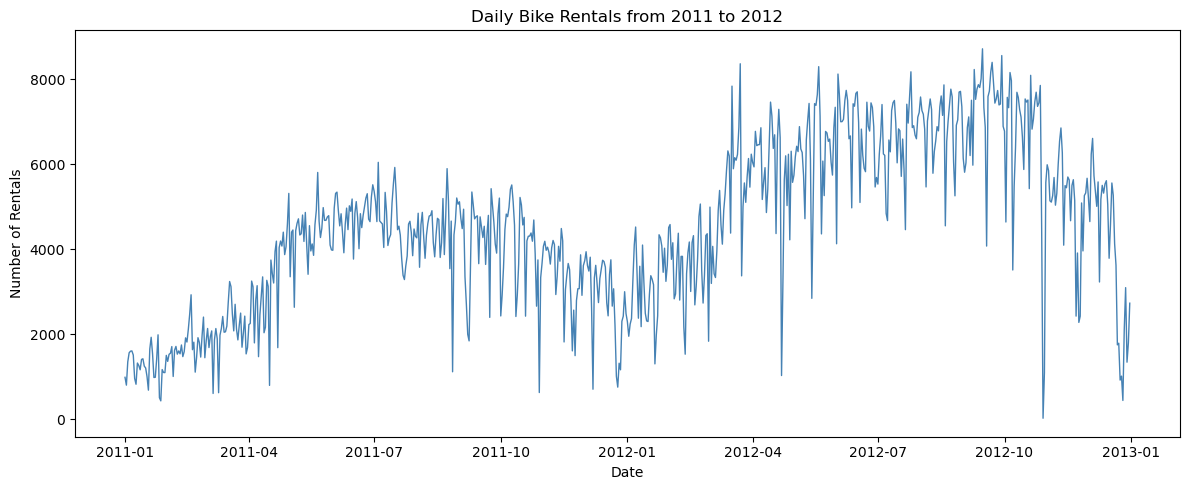

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
plt.plot(df["dteday"], df["cnt"], color="steelblue", linewidth=1)

plt.title("Daily Bike Rentals from 2011 to 2012")
plt.xlabel("Date")
plt.ylabel("Number of Rentals")
plt.tight_layout()
plt.show()

#### Investigation of Low-Demand Days

The daily demand plot contains several sharp declines. The following
table identifies the five lowest rental counts and their corresponding
weather and calendar conditions. These observations are retained
because unusual demand does not automatically indicate a data error.
External causes cannot be established from this table alone.

In [12]:
low_demand_days = df.nsmallest(5, "cnt")[            # Examine the five days with the lowest total rental demand
    [
        "dteday", "cnt", "temp", "hum", "windspeed",
        "weathersit", "holiday", "workingday"
    ]
]

low_demand_days

,dteday,cnt,temp,hum,windspeed,weathersit,holiday,workingday
667,2012-10-29,22,0.440000,0.880000,0.358200,3,0,1
26,2011-01-27,431,0.195000,0.687500,0.113837,1,0,1
725,2012-12-26,441,0.243333,0.823333,0.316546,3,0,1
25,2011-01-26,506,0.217500,0.862500,0.293850,3,0,1
64,2011-03-06,605,0.376522,0.948261,0.343287,2,0,0


### Interpretation of Low-Demand Days

The lowest daily rental count was 22 on 29 October 2012, followed
by 431 on 27 January 2011 and 441 on 26 December 2012. These
observations help identify the sharp drops visible in the daily
demand plot.

Three of the five lowest-demand days have weather-category code 3,
and several have high normalized humidity. However, this small
selection does not establish that weather caused the low demand.
Specific external causes require independent evidence.

These observations were retained because unusually low demand
does not automatically indicate a data error. Such days can create
large forecast errors and are important when discussing model
limitations.

### 3.3 Monthly Demand Patterns
Calculate average daily rentals for each month in each year.
The chart shows higher average demand in every month of 2012, with lower demand near the beginning and end of both years

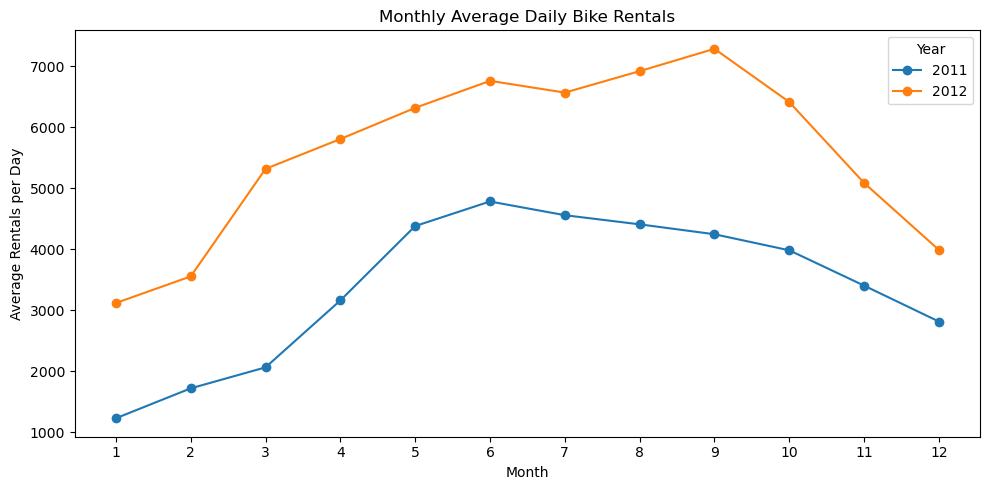

In [13]:
monthly_average = (
    df.groupby([df["dteday"].dt.year, df["dteday"].dt.month])["cnt"]
    .mean()
    .unstack(level=0)
)

monthly_average.plot(figsize=(10, 5), marker="o")

plt.title("Monthly Average Daily Bike Rentals")
plt.xlabel("Month")
plt.ylabel("Average Rentals per Day")
plt.xticks(range(1, 13))
plt.legend(title="Year")
plt.tight_layout()
plt.show()

### 3.4 Weather and Demand Correlations
Examine relationships between weather variables and daily rentals. Temperature and perceived temperature are highly correlated 0.99, so using both could give temperature excessive weight in clustering. Temperature has a positive association with daily rentals 0.63, while humidity −0.10 and wind speed −0.23 have weak negative associations. These correlations describe relationships and do not establish causation.

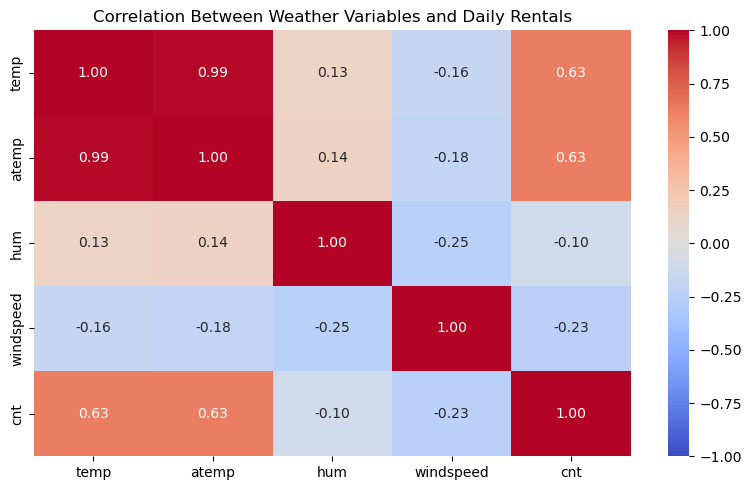

In [14]:
import seaborn as sns

columns = ["temp", "atemp", "hum", "windspeed", "cnt"]

plt.figure(figsize=(8, 5))
sns.heatmap(
    df[columns].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Between Weather Variables and Daily Rentals")
plt.tight_layout()
plt.show()

## 4. Clustering Feature Preparation
### 4.1 Selecting Clustering Features
Select weather and calendar features for grouping similar days

In [15]:
numeric_features = ["temp", "hum", "windspeed"]

categorical_features = [
    "season", "weathersit", "workingday", "holiday"
]

clustering_data = df[
    numeric_features + categorical_features
].copy()

print("Clustering data shape:", clustering_data.shape)
clustering_data.head()

Clustering data shape: (731, 7)


,temp,hum,windspeed,season,weathersit,workingday,holiday
0,0.344167,0.805833,0.160446,1,2,0,0
1,0.363478,0.696087,0.248539,1,2,0,0
2,0.196364,0.437273,0.248309,1,1,1,0
3,0.200000,0.590435,0.160296,1,1,1,0
4,0.226957,0.436957,0.186900,1,1,1,0


### 4.2 Standardization and Categorical Encoding
Prepare numerical and categorical features separately and create the matrix used by both clustering algorithms.
Numerical features were standardized so their different spreads do not dominate distance calculations. Categorical features were one-hot encoded to avoid treating category codes, such as season, as numerical distances. Both clustering algorithms will use the same prepared data for a fair comparison.

In [16]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    ("categorical",
     OneHotEncoder(handle_unknown="ignore", sparse_output=False),
     categorical_features)
])

X = preprocessor.fit_transform(clustering_data)

print("Prepared data shape:", X.shape)
print(X[:5])

Prepared data shape: (731, 14)
[[-0.82666213  1.25017133 -0.38789169  1.          0.          0.
   0.          0.          1.          0.          1.          0.
   1.          0.        ]
 [-0.72109471  0.47911298  0.74960172  1.          0.          0.
   0.          0.          1.          0.          1.          0.
   1.          0.        ]
 [-1.63465665 -1.33927398  0.74663186  1.          0.          0.
   0.          1.          0.          0.          0.          1.
   1.          0.        ]
 [-1.61477973 -0.26318156 -0.38982855  1.          0.          0.
   0.          1.          0.          0.          0.          1.
   1.          0.        ]
 [-1.46741392 -1.34149414 -0.04630665  1.          0.          0.
   0.          1.          0.          0.          0.          1.
   1.          0.        ]]


## 5. Clustering Analysis and Comparison
### Justification for Algorithm Selection

K-means and Ward hierarchical clustering were selected to compare
two approaches to grouping days with similar weather and calendar
conditions.

K-means assigns days to cluster centres and iteratively minimises
within-cluster squared distances. It provides a straightforward
baseline for identifying compact day profiles. However, its results
depend on feature scaling, the number of clusters and initialisation.
Multiple initialisations and a fixed random seed were used to reduce
initialisation sensitivity and support reproducibility.

Ward hierarchical clustering begins with each day as a separate
cluster and repeatedly merges the groups that produce the smallest
increase in within-cluster squared variation. It offers an alternative
without randomly initialised centres, although early merges cannot
be reversed.

Both algorithms are practical for 731 observations and favour compact
clusters. They were applied to the same standardized and encoded
features to make the comparison consistent. Rental counts were
excluded from clustering and examined afterwards to assess the
demand associated with each day profile.
### 5.1 K-means Elbow Method
Calculate within-cluster sum of squared errors for different k values and plot the elbow curve. 
SSE measures how closely observations lie around their cluster centres. It decreases as more clusters are added. An elbow, where the decrease becomes less pronounced, suggests a possible cluster count. We will also use silhouette scores and Davies–Bouldin indices before choosing the final number.

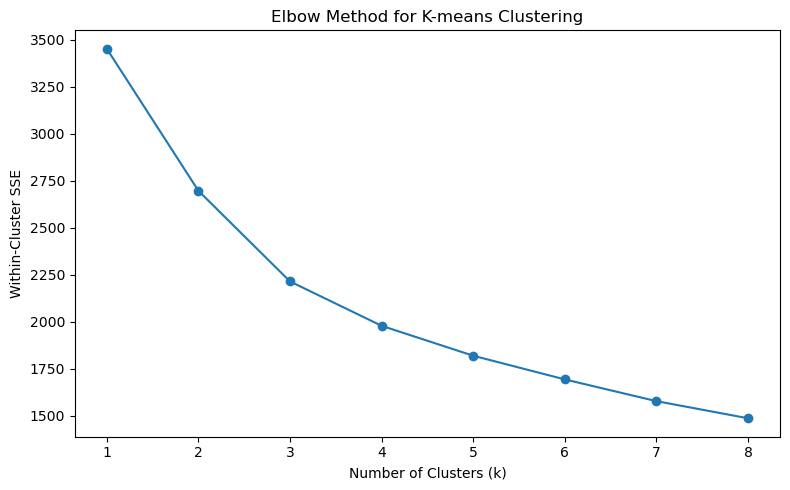

In [17]:
from sklearn.cluster import KMeans
sse = []

for k in range(1, 9):
    kmeans = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=42
    )
    kmeans.fit(X)
    sse.append(kmeans.inertia_)

# 
plt.figure(figsize=(8, 5))
plt.plot(range(1, 9), sse, marker="o")
plt.title("Elbow Method for K-means Clustering")
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Within-Cluster SSE")
plt.xticks(range(1, 9))
plt.tight_layout()
plt.show()

### 5.2 K-means Evaluation
#### Silhouette Score and Davies–Bouldin Index

The silhouette score compares each observation’s average distance
to observations in its own cluster with its average distance to
observations in the nearest alternative cluster. Scores range from
−1 to 1. Higher values indicate better cohesion and separation,
values near zero suggest overlapping groups, and negative values
suggest that an observation may fit another cluster better.

The Davies–Bouldin index compares within-cluster scatter with
distances between cluster centres. For each cluster, it identifies
the most similar other cluster using a scatter-to-separation ratio,
then averages these ratios. Lower values indicate more compact
and better-separated clusters.

The measures can favour different solutions because silhouette uses observation-level distances, while Davies–Bouldin summarises cluster scatter and centre separation. Therefore, both measures were considered alongside cluster sizes and interpretation, with silhouette prioritised for selection.


In [18]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

results = []

for k in range(2, 7):
    kmeans = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=42
    )

    labels = kmeans.fit_predict(X)

    results.append({
        "Clusters": k,
        "Silhouette Score": silhouette_score(X, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X, labels)
    })

kmeans_results = pd.DataFrame(results)
kmeans_results.round(4)

,Clusters,Silhouette Score,Davies-Bouldin Index
0,2,0.2110,1.7996
1,3,0.2141,1.5834
2,4,0.2000,1.5842
3,5,0.2005,1.6199
4,6,0.1930,1.6073


For K-means, three clusters achieve the highest silhouette score (0.2141) and lowest Davies–Bouldin index (1.5834), supporting the elbow curve’s suggestion. However, the modest silhouette score indicates overlapping groups rather than clearly separated categories.

### 5.3 Ward Hierarchical Clustering Evaluation
Hierarchical clustering achieves its highest silhouette score at three clusters 0.1925, while its lowest Davies–Bouldin index occurs at five clusters 1.5810. The measures therefore favour different solutions. Prioritising silhouette and the simpler grouping supports three clusters. At three clusters, K-means performs better on both measures: silhouette 0.2141 versus 0.1925, and Davies–Bouldin 1.5834 versus 1.7139. However, both silhouette scores suggest overlapping groups.

In [19]:
from sklearn.cluster import AgglomerativeClustering

hierarchical_results = []

for k in range(2, 7):
    hierarchical = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )

    labels = hierarchical.fit_predict(X)

    hierarchical_results.append({
        "Clusters": k,
        "Silhouette Score": silhouette_score(X, labels),
        "Davies-Bouldin Index": davies_bouldin_score(X, labels)
    })

hierarchical_results = pd.DataFrame(hierarchical_results)
hierarchical_results.round(4)

,Clusters,Silhouette Score,Davies-Bouldin Index
0,2,0.1617,1.9936
1,3,0.1925,1.7139
2,4,0.1656,1.5900
3,5,0.1641,1.5810
4,6,0.1666,1.6184


### 5.4 Comparison of Clustering Algorithms
K-means has higher silhouette scores than hierarchical clustering across all tested cluster counts. Three clusters give the highest silhouette score for both algorithms. Although hierarchical clustering achieves a slightly lower Davies–Bouldin index at five clusters, K-means with three clusters offers the preferred balance of scores and simplicity. The modest silhouette score indicates that the groups overlap.

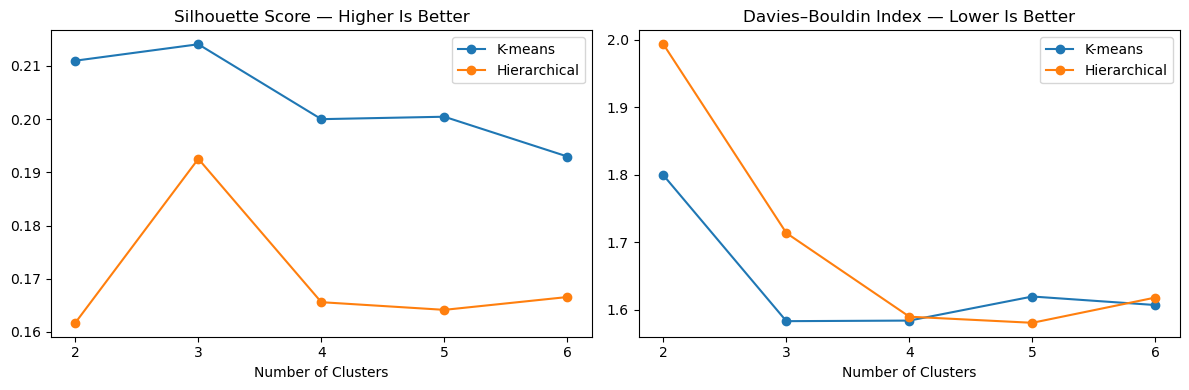

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for name, table in [
    ("K-means", kmeans_results),
    ("Hierarchical", hierarchical_results)
]:
    axes[0].plot(
        table["Clusters"], table["Silhouette Score"],
        marker="o", label=name
    )
    axes[1].plot(
        table["Clusters"], table["Davies-Bouldin Index"],
        marker="o", label=name
    )

axes[0].set_title("Silhouette Score — Higher Is Better")
axes[1].set_title("Davies–Bouldin Index — Lower Is Better")

for ax in axes:
    ax.set_xlabel("Number of Clusters")
    ax.set_xticks(range(2, 7))
    ax.legend()

plt.tight_layout()
plt.show()

### 5.5 Selected Clustering Solution and Day Profiles
Fit the selected clustering solution and keep the original dataset unchanged. And then summarise weather conditions and demand in each group.

Cluster 0 contains 249 relatively humid days, averaging 3,920 rentals. Cluster 1 contains 249 warmer days with lower wind speeds, averaging the highest demand at 5,867 rentals. Cluster 2 contains 233 cooler, windier days, averaging the lowest demand at 3,672 rentals. These are descriptive associations; they do not establish that weather causes the demand differences. Weather values are normalized.

In [21]:
final_kmeans = KMeans(
    n_clusters=3,
    n_init=20,
    random_state=42
)

clustered_df = df.copy()
clustered_df["Cluster"] = final_kmeans.fit_predict(X)

cluster_summary = clustered_df.groupby("Cluster").agg(
    Number_of_Days=("cnt", "size"),
    Average_Temperature=("temp", "mean"),
    Average_Humidity=("hum", "mean"),
    Average_Windspeed=("windspeed", "mean"),
    Average_Daily_Rentals=("cnt", "mean"),
    Working_Day_Share=("workingday", "mean")
)

cluster_summary.round(3)

,Number_of_Days,Average_Temperature,Average_Humidity,Average_Windspeed,Average_Daily_Rentals,Working_Day_Share
Cluster,,,,,,
0,249,0.452,0.765,0.169,3920.361,0.719
1,249,0.683,0.606,0.166,5867.173,0.679
2,233,0.341,0.504,0.240,3672.030,0.652


### 5.6 Rental Demand Distributions by Cluster
Cluster 1 has the highest median daily demand, at approximately 5,800 rentals. Clusters 0 and 2 have lower medians, around 4,000 and 3,400 respectively. The distributions overlap substantially, so the weather and calendar profiles do not completely separate rental demand.

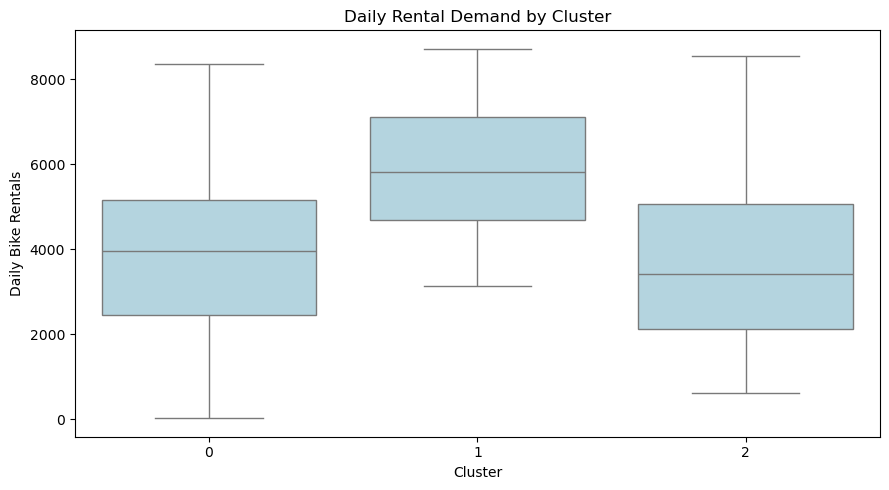

In [22]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=clustered_df,
    x="Cluster",
    y="cnt",
    color="lightblue"
)

plt.title("Daily Rental Demand by Cluster")
plt.xlabel("Cluster")
plt.ylabel("Daily Bike Rentals")
plt.tight_layout()
plt.show()

## 6. Time Series Preparation and Diagnostics
### 6.1 Chronological Fitting Validation and Test Split
Use the date as the index and total rentals as the time series and reserve the final 60 days for testing. And then split the training period for model selection. The dataset was divided chronologically into 611 days for fitting candidate models, 60 days for validation and 60 days for final testing. Validation data help select model settings, while the test data provide a separate evaluation of forecast accuracy. Preserving chronological order prevents future observations from entering model fitting.

In [23]:
series = (
    df.set_index("dteday")["cnt"]
    .sort_index()
    .asfreq("D")
    .astype(float)
)

train = series.iloc[:-60]
test = series.iloc[-60:]

fit_series = train.iloc[:-60]
validation = train.iloc[-60:]

for name, data in [
    ("Fitting", fit_series),
    ("Validation", validation),
    ("Test", test)
]:
    print(
        f"{name}: {len(data)} days, "
        f"{data.index.min().date()} to {data.index.max().date()}"
    )

Fitting: 611 days, 2011-01-01 to 2012-09-02
Validation: 60 days, 2012-09-03 to 2012-11-01
Test: 60 days, 2012-11-02 to 2012-12-31


### 6.2 Weekly Time Series Decomposition
Examine weekly patterns using fitting data only. Decomposition separates daily rentals into a trend, a repeating weekly component and residual variation. A period of seven examines weekly seasonality. Only fitting data are used so validation and test observations remain separate from this exploration

The trend component shows rising demand overall, with a decline around late 2011 and early 2012. The seasonal component displays the weekly pattern extracted using a seven-day period. Residuals contain several large deviations, showing that trend and weekly seasonality do not explain all daily variation. Longer seasonal movements may also appear in the trend component.

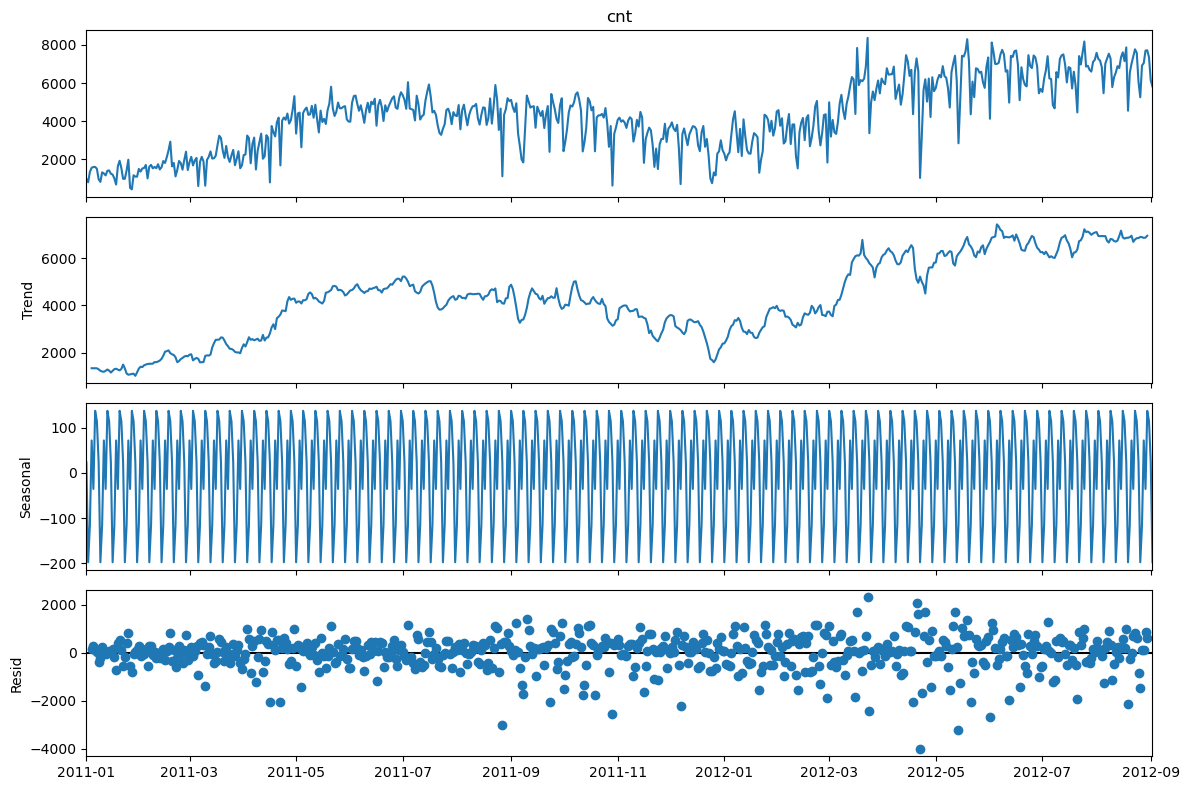

In [24]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    fit_series,
    model="additive",
    period=7
)

fig = decomposition.plot()
fig.set_size_inches(12, 8)
plt.tight_layout()
plt.show()

### 6.3 ADF Test on the Original Series
The test’s null hypothesis is that the series has a unit root. A p-value below 0.05 provides evidence against that hypothesis; a larger value means we cannot reject it.
The ADF p-value is 0.5794, above 0.05, so we cannot reject the unit-root hypothesis. The statistic −1.406 is also less negative than the 5% critical value −2.8664. This supports investigating first differencing, alongside the plotted patterns.

In [25]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(fit_series, autolag="AIC")

print("ADF statistic:", round(adf_result[0], 4))
print("p-value:", round(adf_result[1], 4))

print("Critical values:")
for level, value in adf_result[4].items():
    print(f"{level}: {value:.4f}")

ADF statistic: -1.406
p-value: 0.5794
Critical values:
1%: -3.4414
5%: -2.8664
10%: -2.5694


### 6.4 First Differencing and ADF Test
Calculate the change in rentals from the previous day. Repeat the ADF test and plot the differenced series.

First differencing calculates today’s rentals minus yesterday’s rentals. We apply it and repeat the ADF test to assess whether one difference is appropriate, corresponding to d = 1 in ARIMA. The original fit_series remains unchanged because the model will apply differencing internally when this parameter is specified.

After first differencing, the ADF statistic is −10.9948 and the p-value is below 0.05, providing evidence against a unit root. The differences fluctuate around zero, although large spikes and changes in variability remain. This supports considering one ordinary difference d = 1. The displayed p-value of 0.0 reflects rounding, rather than an exactly zero probability.

ADF statistic: -10.9948
p-value: 0.0


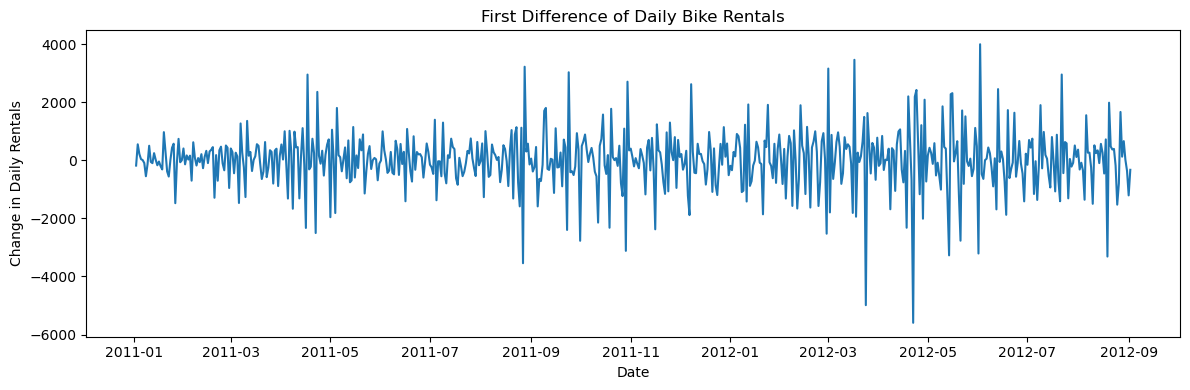

In [26]:
first_difference = fit_series.diff().dropna()
 
adf_diff = adfuller(first_difference, autolag="AIC")

print("ADF statistic:", round(adf_diff[0], 4))
print("p-value:", round(adf_diff[1], 6))

plt.figure(figsize=(12, 4))
plt.plot(first_difference)
plt.title("First Difference of Daily Bike Rentals")
plt.xlabel("Date")
plt.ylabel("Change in Daily Rentals")
plt.tight_layout()
plt.show()

### 6.5 ACF and PACF Analysis
ACF measures correlation with previous observations, while PACF measures the relationship at each lag after accounting for intervening lags. These plots help suggest candidate ARIMA orders and identify possible weekly patterns at lags 7, 14 and 21. Final choices also require model evaluation.

The ACF shows a strong negative correlation at lag 1, while the PACF has several negative short-lag correlations that gradually weaken. This suggests testing models with a low-order moving-average component. The ACF spike at lag 7 also motivates investigating weekly seasonality. These plots suggest candidate orders rather than identifying one definitive model.

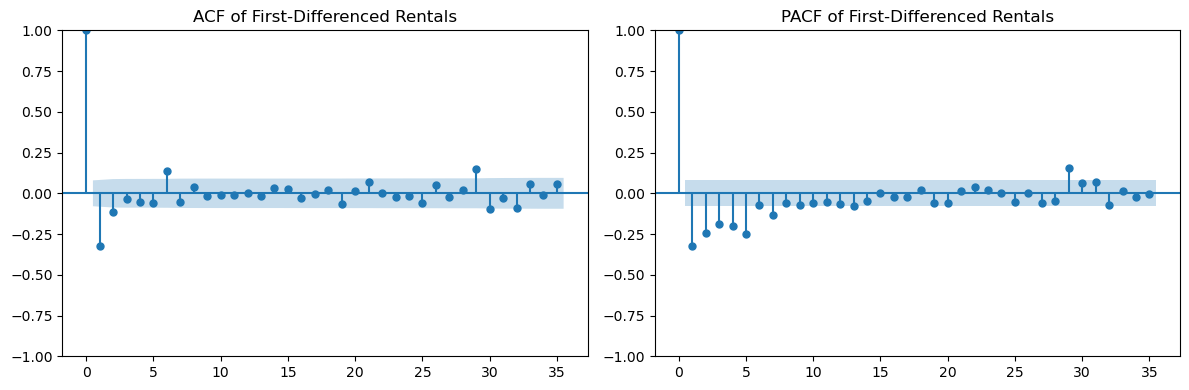

In [27]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

plot_acf(first_difference, lags=35, ax=axes[0])
axes[0].set_title("ACF of First-Differenced Rentals")

plot_pacf(
    first_difference,
    lags=35,
    method="ywm",
    ax=axes[1]
)
axes[1].set_title("PACF of First-Differenced Rentals")

plt.tight_layout()
plt.show()

## 7. Forecast Model Development and Validation
### 7.1 Initial ARIMA Model
ARIMA(0, 1, 1) applies one ordinary difference d = 1 and includes one moving-average term q = 1, with no autoregressive terms p = 0. It is an initial candidate motivated by the ADF test and short-lag correlation patterns. We will compare other settings using validation forecasts before choosing a model.

ARIMA(0,1,1) was fitted using 611 daily observations. Its moving-average coefficient is −0.8157 and statistically significant. The AIC is 9996.359, which provides a reference for comparing candidate models. However, the Ljung–Box p-value is below 0.05, suggesting remaining residual autocorrelation. The other diagnostics indicate non-normal residuals and changing variance, so this initial model needs further assessment.

In [28]:
from statsmodels.tsa.arima.model import ARIMA

arima_model = ARIMA(                                # Use the original fitting series
                                                    # d=1 tells ARIMA to apply first differencing internally
    fit_series,
    order=(0, 1, 1)
)

arima_fit = arima_model.fit()

print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                    cnt   No. Observations:                  611
Model:                 ARIMA(0, 1, 1)   Log Likelihood               -4996.180
Date:                Wed, 28 Oct 2026   AIC                           9996.359
Time:                        15:44:01   BIC                          10005.186
Sample:                    01-01-2011   HQIC                          9999.793
                         - 09-02-2012                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.8157      0.019    -42.589      0.000      -0.853      -0.778
sigma2      7.599e+05    2.7e+04     28.183      0.000    7.07e+05    8.13e+05
Ljung-Box (L1) (Q):                  26.29   Jarque-

### 7.2 Initial ARIMA Validation Forecast
Validation forecasts assess performance on observations excluded from fitting. MAE measures average absolute error, while RMSE gives greater weight to large errors. Lower values indicate better accuracy. These results will help compare candidate models; the final test period remains unused.

ARIMA(0,1,1) produces a nearly constant forecast around 6700 rentals, capturing the general level but missing daily fluctuations and sharp declines. Validation MAE is 1138.60 rentals and RMSE is 1595.14 rentals. The higher RMSE reflects the influence of large forecast errors. A flat forecast is expected for this model beyond its initial forecast steps; it does not indicate a coding error.

Validation MAE: 1138.6
Validation RMSE: 1595.14


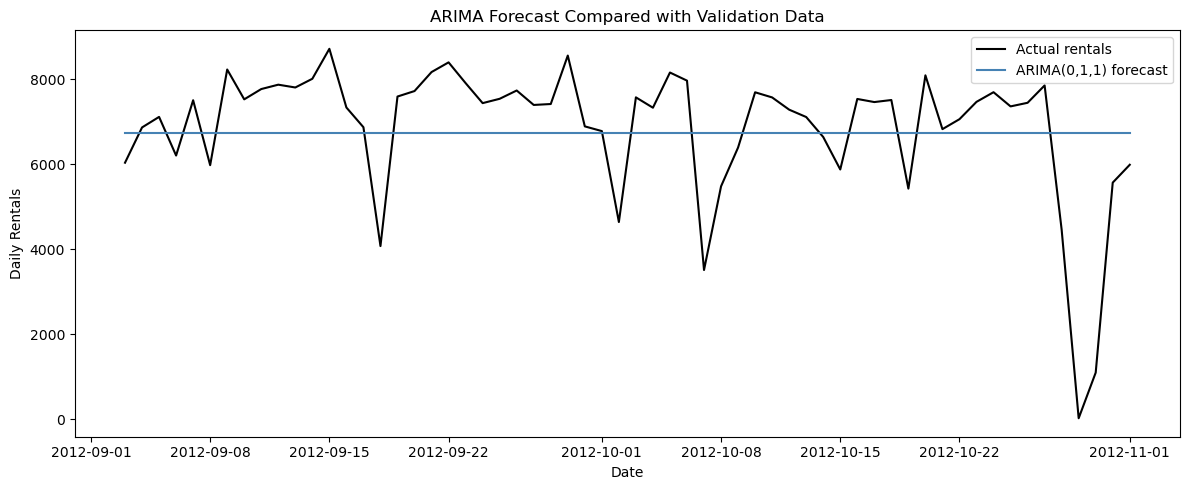

In [29]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

arima_validation_forecast = arima_fit.forecast(                # Forecast the next 60 days without using validation observations
    steps=len(validation)
)

mae = mean_absolute_error(validation, arima_validation_forecast)
rmse = np.sqrt(
    mean_squared_error(validation, arima_validation_forecast)
)

print("Validation MAE:", round(mae, 2))
print("Validation RMSE:", round(rmse, 2))

plt.figure(figsize=(12, 5))
plt.plot(validation, label="Actual rentals", color="black")
plt.plot(
    arima_validation_forecast,
    label="ARIMA(0,1,1) forecast",
    color="steelblue"
)

plt.title("ARIMA Forecast Compared with Validation Data")
plt.xlabel("Date")
plt.ylabel("Daily Rentals")
plt.legend()
plt.tight_layout()
plt.show()

### 7.3 ARIMA Parameter Comparison
Compare a small set of ARIMA orders using the same fitting and validation periods. We consider both d = 0 and d = 1, because the ADF test supports investigating differencing but does not determine which model forecasts best. Validation RMSE is the primary selection measure.

ARIMA(1,0,2) achieves the lowest validation RMSE 1587.979, so it is the preferred ARIMA candidate under our RMSE selection rule. ARIMA(2,1,1) has a lower MAE 1120.957, showing that the preferred model depends on the error measure. The RMSE differences among the leading models are small. Although the ADF test suggested investigating differencing, the undifferenced model forecasts slightly better in this validation window.

In [30]:
candidate_orders = [
    (1, 0, 0),
    (1, 0, 1),
    (1, 0, 2),
    (0, 1, 1),
    (1, 1, 0),
    (1, 1, 1),
    (2, 1, 1)
]

arima_results = []

for order in candidate_orders:
    model = ARIMA(fit_series, order=order)
    fitted = model.fit()

    if not fitted.mle_retvals.get("converged", False):   # Exclude models that did not converge
        print("Not converged:", order)
        continue

    forecast = fitted.forecast(steps=len(validation))

    arima_results.append({
        "Order": order,
        "AIC": fitted.aic,
        "Validation MAE": mean_absolute_error(validation, forecast),
        "Validation RMSE": np.sqrt(
            mean_squared_error(validation, forecast)
        )
    })

arima_comparison = pd.DataFrame(arima_results).sort_values(
    "Validation RMSE"
)

arima_comparison.round(3)

,Order,AIC,Validation MAE,Validation RMSE
2,"(1, 0, 2)",9982.389,1182.408,1587.979
6,"(2, 1, 1)",9961.190,1120.957,1591.510
5,"(1, 1, 1)",9960.721,1125.565,1592.088
3,"(0, 1, 1)",9996.359,1138.595,1595.136
1,"(1, 0, 1)",10017.808,1245.116,1602.946
4,"(1, 1, 0)",10097.525,1591.877,1860.705
0,"(1, 0, 0)",10139.254,2719.804,2915.370


### 7.4 Weekly SARIMA Parameter Comparison
SARIMA adds seasonal terms to ARIMA. We investigate a seasonal period of seven days because the observations are daily and earlier exploration suggested weekly patterns. We compare a small candidate set using validation RMSE, keeping the final test period untouched.

In [31]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarima_candidates = [                    # Each candidate contains: (p,d,q), (P,D,Q,s)
    ((0, 1, 1), (1, 0, 0, 7)),
    ((0, 1, 1), (0, 1, 1, 7)),
    ((1, 1, 1), (1, 0, 1, 7)),
    ((1, 1, 1), (0, 1, 1, 7)),
    ((1, 0, 2), (1, 0, 0, 7)),
    ((1, 0, 2), (0, 1, 1, 7))
]

sarima_results = []

for order, seasonal_order in sarima_candidates:
    trend = "c" if order[1] == 0 and seasonal_order[1] == 0 else "n"            # Include a constant only when neither differencing type is used

    model = SARIMAX(
        fit_series,
        order=order,
        seasonal_order=seasonal_order,
        trend=trend,
        enforce_stationarity=True,
        enforce_invertibility=True
    )

    fitted = model.fit(disp=False, maxiter=200)

    if not fitted.mle_retvals.get("converged", False):
        print("Not converged:", order, seasonal_order)
        continue

    forecast = fitted.forecast(steps=len(validation))

    sarima_results.append({
        "Order": order,
        "Seasonal Order": seasonal_order,
        "AIC": fitted.aic,
        "Validation MAE": mean_absolute_error(validation, forecast),
        "Validation RMSE": np.sqrt(
            mean_squared_error(validation, forecast)
        )
    })

sarima_comparison = pd.DataFrame(sarima_results).sort_values(
    "Validation RMSE"
)

sarima_comparison.round(3)

,Order,Seasonal Order,AIC,Validation MAE,Validation RMSE
4,"(1, 0, 2)","(1, 0, 0, 7)",9984.264,1189.489,1588.824
2,"(1, 1, 1)","(1, 0, 1, 7)",9964.716,1125.571,1592.092
0,"(0, 1, 1)","(1, 0, 0, 7)",10001.215,1138.859,1595.170
5,"(1, 0, 2)","(0, 1, 1, 7)",9882.873,1002.037,1647.051
1,"(0, 1, 1)","(0, 1, 1, 7)",9904.158,1015.893,1649.625
3,"(1, 1, 1)","(0, 1, 1, 7)",9868.945,998.486,1658.238


SARIMA(1,0,2)(1,0,0,7) has the lowest validation RMSE among the seasonal candidates 1,588.824. This is slightly higher than ARIMA(1,0,2), at 1,587.979, so adding weekly seasonality gives no meaningful RMSE improvement in this window. Other SARIMA models have lower MAE but higher RMSE, showing greater sensitivity to large errors. We retain ARIMA as the provisional preference under our RMSE rule.

### 7.5 Validation Comparison with the Weekly Baseline
The seasonal naive baseline repeats the final seven fitting observations throughout the validation period. It provides a simple benchmark for judging whether ARIMA/SARIMA improve forecast accuracy. No validation observations are used to construct its forecasts.

ARIMA has the lowest validation RMSE 1587.979, closely followed by SARIMA 1588.824. Both outperform the weekly baseline on RMSE. However, the baseline has the lowest MAE 1086.683, so neither model is best on every measure. Under our predefined RMSE rule, ARIMA is selected, with little evidence that seasonal terms improve accuracy.

In [32]:
baseline_forecast = pd.Series(                                   # Repeat the last observed week across the validation horizon
    np.resize(fit_series.iloc[-7:].to_numpy(), len(validation)),
    index=validation.index
)

baseline_mae = mean_absolute_error(validation, baseline_forecast)
baseline_rmse = np.sqrt(
    mean_squared_error(validation, baseline_forecast)
)

validation_comparison = pd.DataFrame([                        # Compare each model family's best validation candidate
    {
        "Model": "ARIMA",
        "Validation MAE": arima_comparison.iloc[0]["Validation MAE"],
        "Validation RMSE": arima_comparison.iloc[0]["Validation RMSE"]
    },
    {
        "Model": "SARIMA",
        "Validation MAE": sarima_comparison.iloc[0]["Validation MAE"],
        "Validation RMSE": sarima_comparison.iloc[0]["Validation RMSE"]
    },
    {
        "Model": "Weekly baseline",
        "Validation MAE": baseline_mae,
        "Validation RMSE": baseline_rmse
    }
]).sort_values("Validation RMSE")

validation_comparison.round(3)

,Model,Validation MAE,Validation RMSE
0,ARIMA,1182.408,1587.979
1,SARIMA,1189.489,1588.824
2,Weekly baseline,1086.683,1688.414


## 8. Final Forecast Evaluation
### 8.1 Refitting Selected Models and Test Accuracy
After selecting specifications using validation data, both models are refitted on the full training period. Their forecasts are evaluated against the untouched final 60 days using MAE and RMSE. The test results assess performance; they are not used to retune parameters.

SARIMA achieves the lowest test MAE 1184.217 and RMSE 1794.118, slightly outperforming ARIMA. Both models outperform the weekly baseline, whose RMSE is 3271.444. Although validation selected ARIMA, SARIMA performs better in this final test window. This difference shows that model rankings can change across periods; the test results should not be used to retune the models.

In [33]:
best_arima_order = tuple(arima_comparison.iloc[0]["Order"])  # Refit the selected ARIMA specification

final_arima = ARIMA(
    train,
    order=best_arima_order
).fit()

best_sarima_order = tuple(sarima_comparison.iloc[0]["Order"])  # Refit the selected SARIMA specification
best_seasonal_order = tuple(
    sarima_comparison.iloc[0]["Seasonal Order"]
)

sarima_trend = (
    "c"
    if best_sarima_order[1] == 0 and best_seasonal_order[1] == 0
    else "n"
)

final_sarima = SARIMAX(
    train,
    order=best_sarima_order,
    seasonal_order=best_seasonal_order,
    trend=sarima_trend,
    enforce_stationarity=True,
    enforce_invertibility=True
).fit(disp=False, maxiter=200)

assert final_arima.mle_retvals.get("converged", False)   # Check convergence before evaluating forecasts
assert final_sarima.mle_retvals.get("converged", False)

arima_test_forecast = final_arima.forecast(steps=len(test)) # Forecast the untouched test period
sarima_test_forecast = final_sarima.forecast(steps=len(test))

baseline_test_forecast = pd.Series(
    np.resize(train.iloc[-7:].to_numpy(), len(test)),
    index=test.index
)

test_results = []

for name, forecast in [
    ("ARIMA", arima_test_forecast),
    ("SARIMA", sarima_test_forecast),
    ("Weekly baseline", baseline_test_forecast)
]:
    test_results.append({
        "Model": name,
        "Test MAE": mean_absolute_error(test, forecast),
        "Test RMSE": np.sqrt(mean_squared_error(test, forecast))
    })

test_comparison = pd.DataFrame(test_results).sort_values("Test RMSE")
test_comparison.round(3)

,Model,Test MAE,Test RMSE
1,SARIMA,1184.217,1794.118
0,ARIMA,1211.887,1836.784
2,Weekly baseline,2630.533,3271.444


### 8.2 Forecasts Compared with Actual Test Demand
This plot compares fixed-origin forecasts with actual rentals during the final 60 days. It helps identify whether models capture the demand level and fluctuations, and where large forecast errors occur.

ARIMA and SARIMA produce similar, nearly flat forecasts around 5400 rentals. They capture the general demand level but miss daily fluctuations and the sharp decline towards late December. The weekly baseline repeats extreme values from the last training week, contributing to its larger errors. SARIMA has slightly lower test errors, but the graph shows limitations in both models.

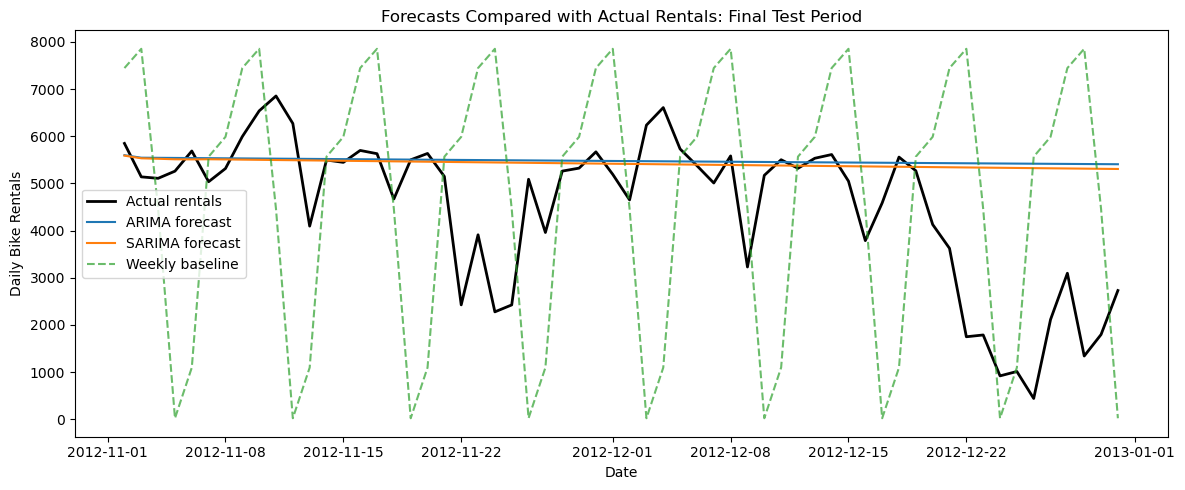

In [34]:
plt.figure(figsize=(12, 5))

plt.plot(test, label="Actual rentals", color="black", linewidth=2)
plt.plot(arima_test_forecast, label="ARIMA forecast")
plt.plot(sarima_test_forecast, label="SARIMA forecast")
plt.plot(
    baseline_test_forecast,
    label="Weekly baseline",
    linestyle="--",
    alpha=0.7
)

plt.title("Forecasts Compared with Actual Rentals: Final Test Period")
plt.xlabel("Date")
plt.ylabel("Daily Bike Rentals")
plt.legend()
plt.tight_layout()
plt.show()

### 8.3 Residual Autocorrelation Diagnostics
Residuals are differences between observed and fitted values. The Ljung–Box test checks for remaining autocorrelation. A p-value below 0.05 suggests that the model has not captured all temporal structure; a larger value means the test does not detect significant autocorrelation at the examined lags.

Both ARIMA and SARIMA have Ljung–Box p-values below 0.05 at lags 14 and 28. This indicates remaining residual autocorrelation, suggesting that neither model fully captures the temporal structure. Although SARIMA has slightly lower test errors, both models have limitations. These diagnostics do not justify retuning models using the final test data.

In [35]:
from statsmodels.stats.diagnostic import acorr_ljungbox

for name, fitted in [
    ("ARIMA", final_arima),
    ("SARIMA", final_sarima)
]:
    residuals = fitted.resid.iloc[              # Exclude the initial observations affected by initialization
        max(14, int(fitted.loglikelihood_burn)):
    ]

    p, d, q = fitted.model.order                  # Extract model orders for the test's degrees-of-freedom adjustment
    P, D, Q, s = fitted.model.seasonal_order

    print(f"\n{name} residual diagnostics:")

    display(
        acorr_ljungbox(
            residuals,
            lags=[14, 28],
            model_df=p + q + P + Q,
            return_df=True
        ).round(4)
    )


ARIMA residual diagnostics:


,lb_stat,lb_pvalue
14,21.5738,0.0279
28,39.9390,0.0296



SARIMA residual diagnostics:


,lb_stat,lb_pvalue
14,21.5648,0.0175
28,39.8451,0.0222


### 8.4 Prediction Intervals and Test Coverage
Prediction intervals express uncertainty around future rentals under the model’s assumptions. We compare the nominal 95% interval with actual test observations. Remaining residual autocorrelation may weaken the reliability of these intervals

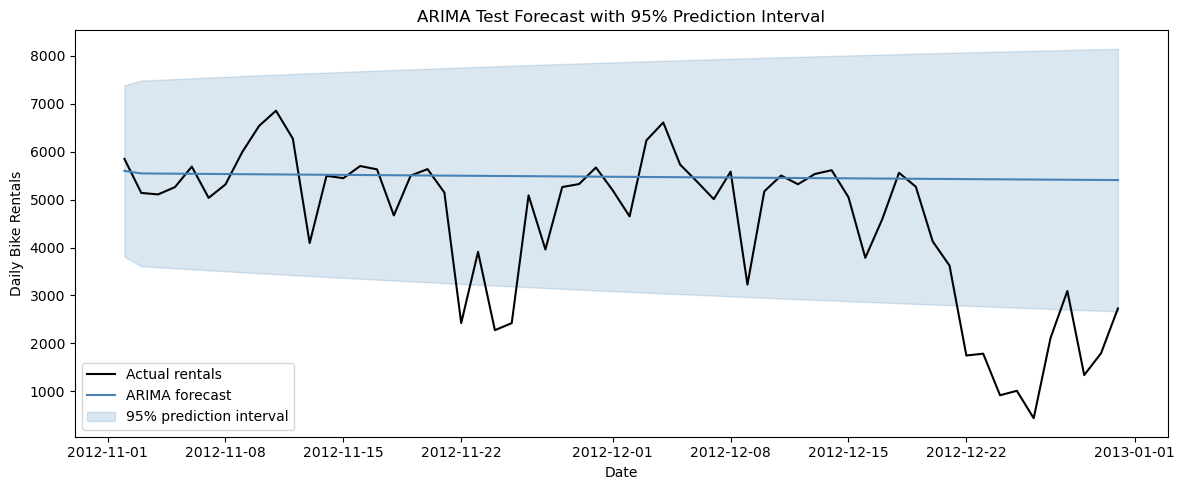

Test interval coverage: 81.7%


In [36]:
forecast_result = final_arima.get_forecast(steps=len(test))    # Obtain forecasts and their prediction intervals
forecast_mean = forecast_result.predicted_mean
interval = forecast_result.conf_int(alpha=0.05)

plt.figure(figsize=(12, 5))

plt.plot(test, color="black", label="Actual rentals")
plt.plot(forecast_mean, color="steelblue", label="ARIMA forecast")

plt.fill_between(
    test.index,
    interval.iloc[:, 0],
    interval.iloc[:, 1],
    color="steelblue",
    alpha=0.2,
    label="95% prediction interval"
)

plt.title("ARIMA Test Forecast with 95% Prediction Interval")
plt.xlabel("Date")
plt.ylabel("Daily Bike Rentals")
plt.legend()
plt.tight_layout()
plt.show()

coverage = (                          # Measure the proportion of test observations inside the interval
    (test >= interval.iloc[:, 0]) &
    (test <= interval.iloc[:, 1])
).mean()

print(f"Test interval coverage: {coverage:.1%}")

The 95% prediction interval contains 81.7% of the test observations, below its nominal coverage. Several low-demand days, particularly in late December, fall below the lower bound. This shows undercoverage in this test window and suggests that the model does not adequately represent downward demand changes and forecast uncertainty. Remaining residual autocorrelation adds to these limitations.

## 9. Overall Conclusion
This project analyzed daily demand for bike sharing, based on 731 observations, which spanned the period 2011-2012. The exploratory analysis revealed that there were higher monthly average demands during 2012, seasonal variation and a few steep decreases in demands. These patterns illustrate the need to think about the volume of change in demand as well as unusual observations when planning the availability of bikes.
Standardized weather features and the encoded calendar features were compared by using the k-means and Ward hierarchical clustering approaches. K-means with three clusters was chosen, which gave a silhouette score of 0.2141 and a Davies–Bouldin index of 1.5834. The groups that emerged were those of relatively humid days, warmer days and cooler and windier days. The greatest average demand, around 5,867 rentals, occurred on the warmer days. But there is some overlap in the distributions of daily rental counts and the modest silhouette scores suggest that the groups do not form a well-defined set of categories. Such associations are not causal.

Candidate models were fitted and selected using chronological fitting and validation periods, then evaluated on an untouched 60-day test period. The lowest RMSE for the validation period was obtained by ARIMA(1,0,2). On the test period, SARIMA(1,0,2)(1,0,0,7) performed slightly better, with MAE of 1,184.217 and RMSE of 1,794.118 rentals. Both models outperformed the weekly seasonal-naive baseline on test MAE and RMSE, but their nearly flat forecasts missed daily fluctuations and the late-December decline.

Both models showed considerable residual autocorrelation, and the nominal 95% interval for the ARIMA model only included 81.7% of the test observations. Therefore, the results are not a reliable operational forecasting system, but are used as a starting planning point. Additional forecast origins and weather-related predictors should be used in further work using recent data. The information at the station level would also be required for particular bicycle redistribution decisions.

## 10. References
Fanaee-T, H. (2013) Bike Sharing [Dataset]. UCI Machine Learning Repository. 
Available at: https://doi.org/10.24432/C5W894

Dr. Muhammad Iqbal (2026) Machine Learning for Business:
CCT College Dublin. Unpublished teaching material.

Hyndman, R.J. and Athanasopoulos, G. (2021) Forecasting: Principles and Practice. 3rd edn. Melbourne: OTexts. 
Available at: https://otexts.com/fpp3/ 

Matplotlib (n.d.) Using Matplotlib. 
Available at: https://matplotlib.org/stable/users/index.html 

NumPy Developers (n.d.) NumPy documentation. 
Available at: https://numpy.org/doc/stable/ 

pandas (n.d.) pandas documentation. 
Available at: https://pandas.pydata.org/docs/ 

scikit-learn (n.d.a) Clustering. 
Available at: https://scikit-learn.org/stable/modules/clustering.html 

scikit-learn (n.d.b) Preprocessing data. 
Available at: https://scikit-learn.org/stable/modules/preprocessing.html 

seaborn (n.d.) seaborn: statistical data visualization. 
Available at: https://seaborn.pydata.org/ 

statsmodels (n.d.a) statsmodels.stats.diagnostic.acorr_ljungbox. 
Available at: Ljung–Box documentation 

statsmodels (n.d.b) Time series analysis. 
Available at: https://www.statsmodels.org/stable/tsa.html 